<img
  src="https://raw.githubusercontent.com/k-git-uconn/OPIM-5604-PredictiveModeling/main/5604_AssignmentImage.bmp"
  width="40%"
  alt="OPIM 5641 assignment banner"
/>

**Submitted Date: 11-18-2026**

# Environment Setup

In [1]:
# import modules

import pandas as pd # for data viz and wrangling
import numpy as np # for 'numeric python'
import matplotlib.pyplot as plt # for data viz (more complex than pylab)
import seaborn as sns
from pylab import * # for data viz (import * means 'import all of the functions')

from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn import metrics
from scipy import stats
import statsmodels.api as sm


# @1. Read in the Spotify dataset and determine how many rows and columns it has.

In [2]:
# read data
# on the lefthand side, navigate to your data and copy the path
data_file = 'https://raw.githubusercontent.com/k-git-uconn/OPIM-5604-PredictiveModeling/main/M10/M10Assignment/spotify-2023_modeling.csv'

df = pd.read_csv(data_file)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Number of rows: 902
Number of columns: 26


,track_name,artist(s)_name,streams,streams (M),artist_count,released_year,Johnson Su Transform to Normal released_year,released_month,released_month_reduced,released_day,...,in_shazam_charts,bpm,mode,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
0,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",141381703.0,141.381703,2,2023,1.572000,7,Low,14,...,826,125,Major,80,89,83,31,0,8,4
1,LALA,Myke Towers,133716286.0,133.716286,1,2023,1.572000,3,Low,23,...,382,92,Major,71,61,74,7,0,10,4
2,vampire,Olivia Rodrigo,140003974.0,140.003974,1,2023,1.572000,6,Low,30,...,949,138,Major,51,32,53,17,0,31,6
3,Cruel Summer,Taylor Swift,800840817.0,800.840817,1,2019,-0.907868,8,High,23,...,548,170,Major,55,58,72,11,0,11,15
4,WHERE SHE GOES,Bad Bunny,303236322.0,303.236322,1,2023,1.572000,5,Low,18,...,425,144,Minor,65,23,80,14,63,11,6


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 902 entries, 0 to 901
Data columns (total 26 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   track_name                                    902 non-null    object 
 1   artist(s)_name                                902 non-null    object 
 2   streams                                       902 non-null    float64
 3   streams (M)                                   902 non-null    float64
 4   artist_count                                  902 non-null    int64  
 5   released_year                                 902 non-null    int64  
 6   Johnson Su Transform to Normal released_year  902 non-null    float64
 7   released_month                                902 non-null    int64  
 8   released_month_reduced                        902 non-null    object 
 9   released_day                                  902 non-null    int

# @2. The target variable for this dataset is the streams (M) column.  Check the datatype of streams (M).  

In [6]:
print(df['streams (M)'].dtype)

float64


The target variable is a continuous numerical variable, making it suitable for a regression problem.

We will also be dropping the track and artist names because they have many unique values, and converting the remaining categorical predictors into dummy variables.

# @3. Partition the data into a 60/20/20 split.

In [7]:
from sklearn.model_selection import train_test_split

# Define the target variable
target = 'streams (M)'

# Remove target and unnecessary text/duplicate columns
features = df.drop(columns=[
    'track_name',
    'artist(s)_name',
    'streams',
    target
])

# Convert categorical variables into dummy variables
categorical_cols = features.select_dtypes(include=['object']).columns

features = pd.get_dummies(
    features,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

target_variable = df[target]

# Step 1: Split data into 60% training and 40% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    features, target_variable,
    test_size=0.4,
    random_state=42
)

# Step 2: Split the remaining 40% into 20% validation and 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42
)

# Print the shapes of the resulting datasets
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (541, 22) (541,)
Validation set shape: (180, 22) (180,)
Test set shape: (181, 22) (181,)


# @4. Build a neural network to predict streams (M) using all predictors.

Let's build a neural network model.  First we standardize the predictors then we fit the model.

In [8]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error # Import mean_squared_error to calculate MSE first

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


# Build the neural network model
nn_model = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=2000, random_state=42, learning_rate_init=0.01)

# Train the model
nn_model.fit(X_train_scaled, y_train)

# Make predictions on the validation set
y_pred_val = nn_model.predict(X_val_scaled)

# Evaluate the model
mse = mean_squared_error(y_val, y_pred_val)
rmse = np.sqrt(mse) # Calculate RMSE
r2 = r2_score(y_val, y_pred_val)

print(f"Root Mean Squared Error on validation set: {rmse}") # Print RMSE
print(f"R-squared on validation set: {r2}")

Root Mean Squared Error on validation set: 306.971934927667
R-squared on validation set: 0.6300928016857561


The neural network achieved an RMSE of 306.97 and an R-squared value of 0.63 on the validation dataset.

This indicates that the model explains approximately 63% of the variation in song streams. Although the model captures meaningful patterns in the data, there is still room for improvement in prediction accuracy.

# @5. Check model performance by partition with RMSE, R Squared, distribution of residuals, and actual by predicted plots.

In [9]:
from sklearn.metrics import mean_squared_error, r2_score

# Make predictions on all three sets
y_pred_train = nn_model.predict(X_train_scaled)
y_pred_val = nn_model.predict(X_val_scaled)
y_pred_test = nn_model.predict(X_test_scaled)

# Evaluate performance on the training set
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
r2_train = r2_score(y_train, y_pred_train)

# Evaluate performance on the validation set
rmse_val = np.sqrt(mean_squared_error(y_val, y_pred_val))
r2_val = r2_score(y_val, y_pred_val)

# Evaluate performance on the test set
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)

# Print the results
print("Neural Network Model Performance:")
print(f"  Training Set: RMSE = {rmse_train:.2f}, R-squared = {r2_train:.2f}")
print(f"  Validation Set: RMSE = {rmse_val:.2f}, R-squared = {r2_val:.2f}")
print(f"  Test Set: RMSE = {rmse_test:.2f}, R-squared = {r2_test:.2f}")

Neural Network Model Performance:
  Training Set: RMSE = 10.25, R-squared = 1.00
  Validation Set: RMSE = 306.97, R-squared = 0.63
  Test Set: RMSE = 280.55, R-squared = 0.67


Training performance: RMSE of 10.25 and R² of 1.00 indicate that the model almost perfectly fits the training data.



Validation performance: R² drops to 0.63, suggesting that the model does not generalize as well to unseen data.



Test performance: R² of 0.67 indicates that the model explains approximately 67% of the variation in streaming numbers.



Overfitting: The large gap between training and validation performance suggests that the model has memorized training patterns rather than learning relationships that generalize well.

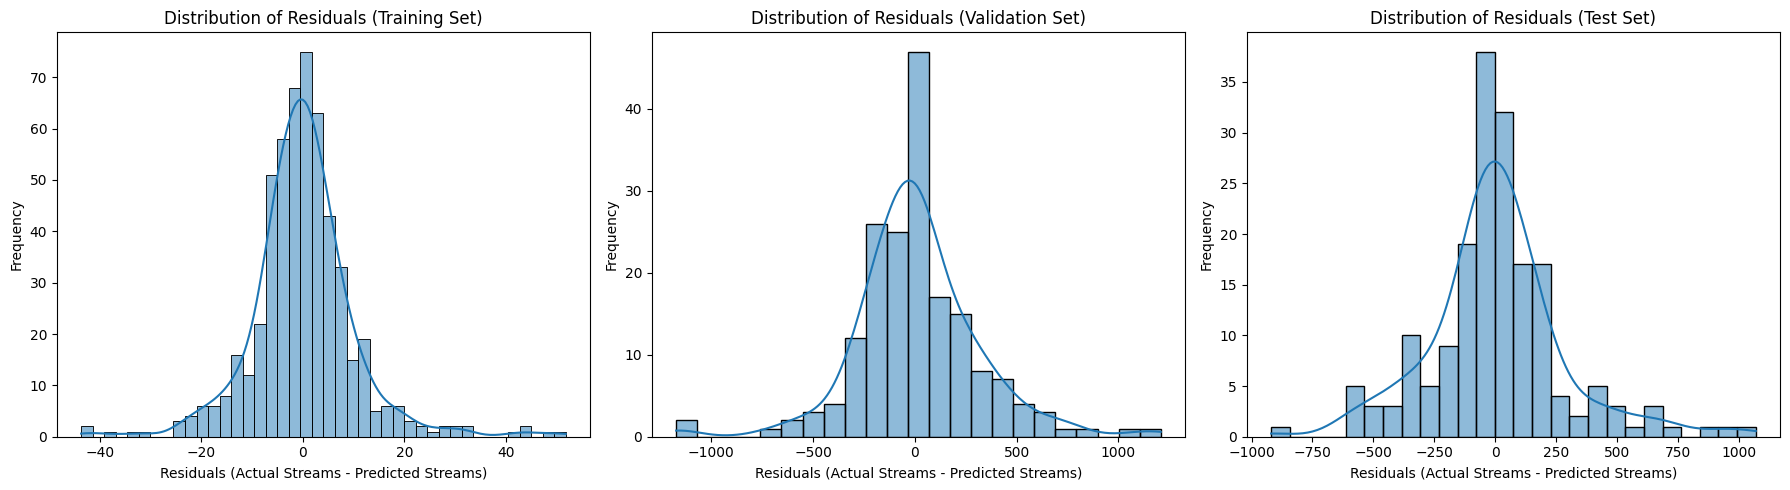


Summary Statistics of Residuals (Training Set):
count    541.000000
mean       0.040250
std       10.263655
min      -43.671609
25%       -4.890387
50%       -0.137478
75%        4.378701
max       51.760375
Name: streams (M), dtype: float64

Summary Statistics of Residuals (Validation Set):
count     180.000000
mean       11.567747
std       307.609563
min     -1173.235476
25%      -155.392034
50%        -4.840488
75%       140.519003
max      1207.687632
Name: streams (M), dtype: float64

Summary Statistics of Residuals (Test Set):
count     181.000000
mean        5.236213
std       281.281464
min      -919.467452
25%      -109.763932
50%       -10.563500
75%       115.038262
max      1070.802818
Name: streams (M), dtype: float64


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals for all three sets
residuals_train = y_train - y_pred_train
residuals_val = y_val - y_pred_val
residuals_test = y_test - y_pred_test

# Create a figure and a set of subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5)) # 1 row, 3 columns

# Plot the distribution of residuals for the training set
sns.histplot(residuals_train, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Residuals (Training Set)')
axes[0].set_xlabel('Residuals (Actual Streams - Predicted Streams)')
axes[0].set_ylabel('Frequency')

# Plot the distribution of residuals for the validation set
sns.histplot(residuals_val, kde=True, ax=axes[1])
axes[1].set_title('Distribution of Residuals (Validation Set)')
axes[1].set_xlabel('Residuals (Actual Streams - Predicted Streams)')
axes[1].set_ylabel('Frequency')

# Plot the distribution of residuals for the test set
sns.histplot(residuals_test, kde=True, ax=axes[2])
axes[2].set_title('Distribution of Residuals (Test Set)')
axes[2].set_xlabel('Residuals (Actual Streams - Predicted Streams)')
axes[2].set_ylabel('Frequency')

# Adjust layout to prevent overlapping titles/labels
plt.tight_layout()
plt.show()

# Also display summary statistics of residuals for all three sets
print("\nSummary Statistics of Residuals (Training Set):")
print(residuals_train.describe())

print("\nSummary Statistics of Residuals (Validation Set):")
print(residuals_val.describe())

print("\nSummary Statistics of Residuals (Test Set):")
print(residuals_test.describe())

1. Training residuals: The mean is close to zero and standard deviation is only 10.26, indicating very small prediction errors on training data.

2. Validation residuals: Standard deviation increases significantly to 307.61, with errors ranging from -1,173.24 to 1,207.69.

3. Test residuals: Standard deviation is 281.28, confirming that prediction errors remain substantially higher on unseen data.

4. Mean residuals: The validation and test means are relatively close to zero, suggesting limited overall systematic prediction bias, although individual prediction errors are large.

5. Overfitting: The substantial difference between training and validation/test residual distributions indicates that the model fits the training data much better than unseen observations.

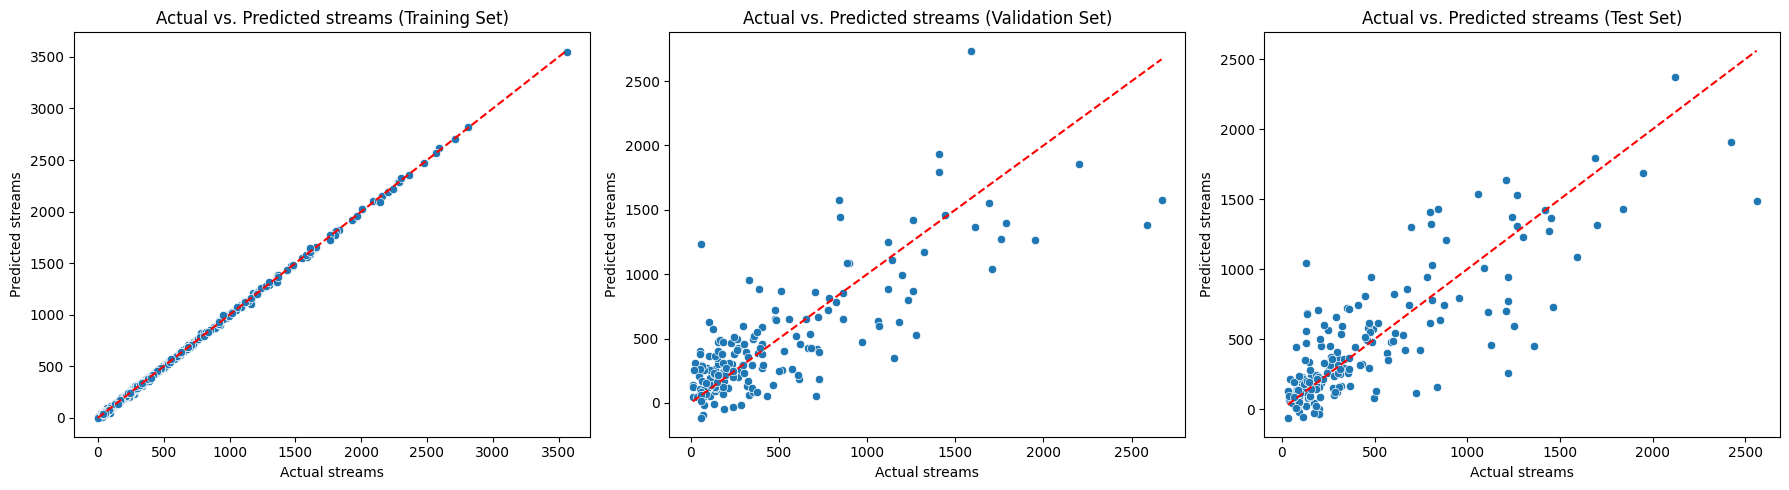

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure and a set of subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5)) # 1 row, 3 columns

# Plot actual vs. predicted for the training set
sns.scatterplot(x=y_train, y=y_pred_train, ax=axes[0])
axes[0].set_title('Actual vs. Predicted streams (Training Set)')
axes[0].set_xlabel('Actual streams')
axes[0].set_ylabel('Predicted streams')
axes[0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--') # Add a diagonal line

# Plot actual vs. predicted for the validation set
sns.scatterplot(x=y_val, y=y_pred_val, ax=axes[1])
axes[1].set_title('Actual vs. Predicted streams (Validation Set)')
axes[1].set_xlabel('Actual streams')
axes[1].set_ylabel('Predicted streams')
axes[1].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--') # Add a diagonal line


# Plot actual vs. predicted for the test set
sns.scatterplot(x=y_test, y=y_pred_test, ax=axes[2])
axes[2].set_title('Actual vs. Predicted streams (Test Set)')
axes[2].set_xlabel('Actual streams')
axes[2].set_ylabel('Predicted streams')
axes[2].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--') # Add a diagonal line


# Adjust layout to prevent overlapping titles/labels
plt.tight_layout()
plt.show()

# @6. Comment on the model performance.  What did you observe in the results?

The Actual vs. Predicted plots show a clear difference between training and unseen data performance.

The training predictions are almost perfectly aligned with the reference line, indicating an excellent fit. However, the validation and test predictions are more widely scattered, particularly for songs with higher streaming numbers.

 The model captures the general relationship between actual and predicted streams but struggles to predict some observations accurately.

 The similar patterns in the validation and test plots suggest consistent performance on unseen data.

 Overall, the plots confirm that the neural network is overfitting the training data and has limited generalization performance.

# @7. Build a linear regression model to predict streams (M).

In [13]:
from sklearn.linear_model import LinearRegression

# Initialize Linear Regression model
lr_model = LinearRegression()

# Train the model using training data
lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


# @8. Check model performance by partition with RMSE, R Squared, distribution of residuals, and actual by predicted plots.

In [14]:
# Predictions for all three datasets
y_train_pred_lr = lr_model.predict(X_train)
y_val_pred_lr = lr_model.predict(X_val)
y_test_pred_lr = lr_model.predict(X_test)

from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Training Set
train_rmse_lr = np.sqrt(mean_squared_error(y_train, y_train_pred_lr))
train_r2_lr = r2_score(y_train, y_train_pred_lr)

# Validation Set
val_rmse_lr = np.sqrt(mean_squared_error(y_val, y_val_pred_lr))
val_r2_lr = r2_score(y_val, y_val_pred_lr)

# Test Set
test_rmse_lr = np.sqrt(mean_squared_error(y_test, y_test_pred_lr))
test_r2_lr = r2_score(y_test, y_test_pred_lr)

print("Linear Regression Model Performance:")
print(f"Training Set: RMSE = {train_rmse_lr:.2f}, R-squared = {train_r2_lr:.2f}")
print(f"Validation Set: RMSE = {val_rmse_lr:.2f}, R-squared = {val_r2_lr:.2f}")
print(f"Test Set: RMSE = {test_rmse_lr:.2f}, R-squared = {test_r2_lr:.2f}")

Linear Regression Model Performance:
Training Set: RMSE = 234.56, R-squared = 0.81
Validation Set: RMSE = 239.59, R-squared = 0.77
Test Set: RMSE = 276.71, R-squared = 0.68


The Linear Regression model achieved an R-squared value of 0.81 on the training dataset, 0.77 on the validation dataset, and 0.68 on the test dataset.

Its performance remained relatively consistent across the three datasets, suggesting reasonable generalization with limited overfitting.

Compared with the Neural Network, Linear Regression performed better on the validation dataset and slightly better on the test dataset.

Although the Neural Network achieved nearly perfect training performance, it showed signs of significant overfitting.

Overall, **Linear Regression appears to be the more reliable model** for predicting song streams based on its more consistent performance on unseen data.

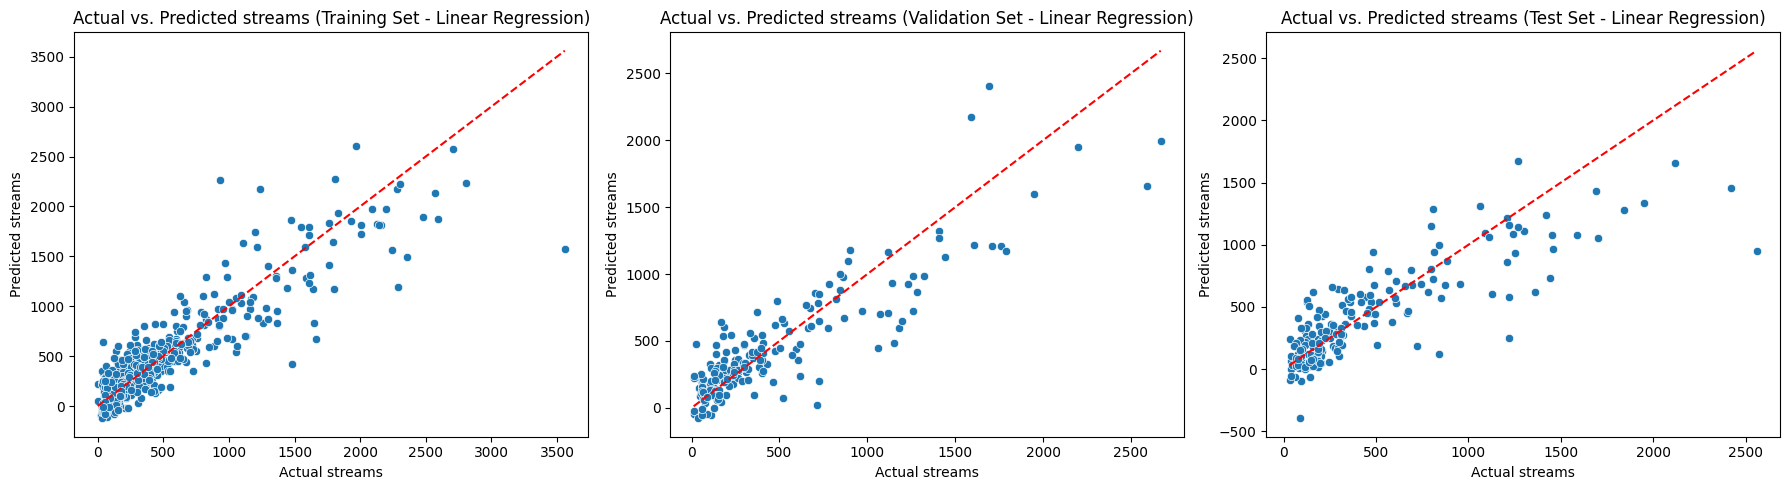

In [15]:
# Create a figure and a set of subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Training Set
sns.scatterplot(x=y_train, y=y_train_pred_lr, ax=axes[0])
axes[0].set_title('Actual vs. Predicted streams (Training Set - Linear Regression)')
axes[0].set_xlabel('Actual streams')
axes[0].set_ylabel('Predicted streams')
axes[0].plot([y_train.min(), y_train.max()],
             [y_train.min(), y_train.max()], 'r--')

# Validation Set
sns.scatterplot(x=y_val, y=y_val_pred_lr, ax=axes[1])
axes[1].set_title('Actual vs. Predicted streams (Validation Set - Linear Regression)')
axes[1].set_xlabel('Actual streams')
axes[1].set_ylabel('Predicted streams')
axes[1].plot([y_val.min(), y_val.max()],
             [y_val.min(), y_val.max()], 'r--')

# Test Set
sns.scatterplot(x=y_test, y=y_test_pred_lr, ax=axes[2])
axes[2].set_title('Actual vs. Predicted streams (Test Set - Linear Regression)')
axes[2].set_xlabel('Actual streams')
axes[2].set_ylabel('Predicted streams')
axes[2].plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')

plt.tight_layout()
plt.show()

Unlike the Neural Network, the training predictions are not perfectly aligned with the reference line, suggesting less overfitting.

The validation and test plots show similar patterns, indicating that the model generalizes reasonably well to unseen data. However, some observations, particularly songs with higher streaming numbers, show larger prediction errors, with the model tending to underpredict certain high-streaming songs.

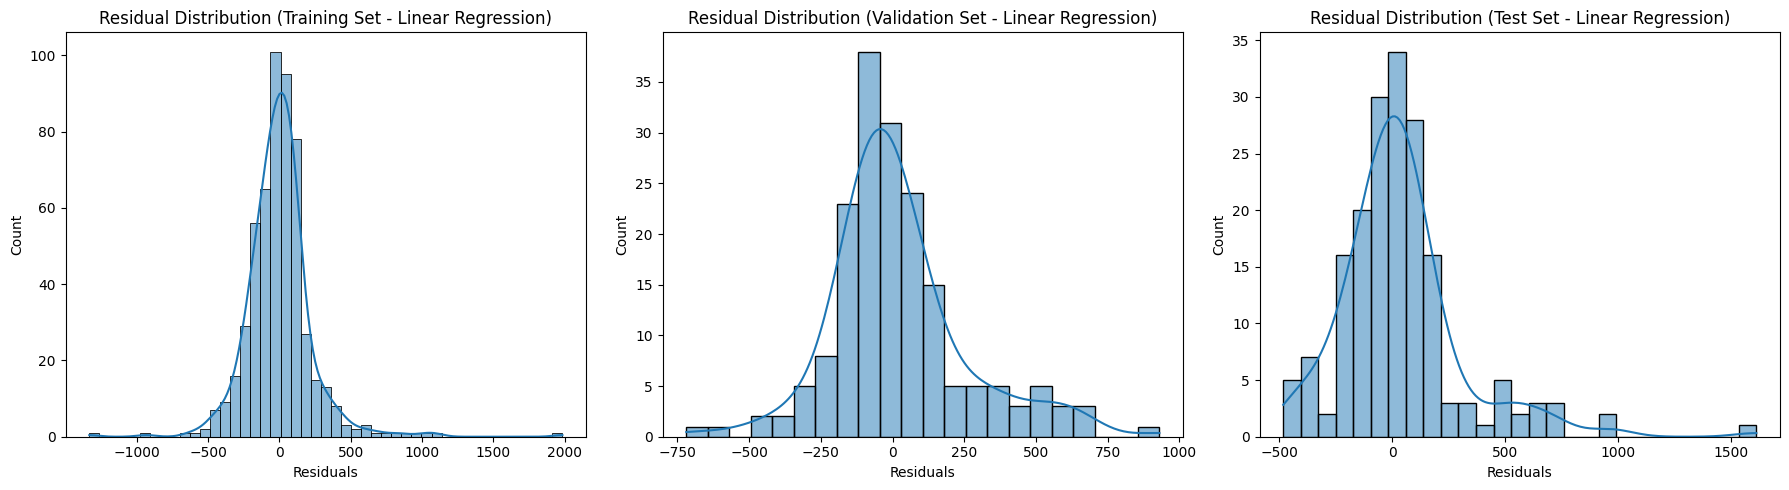

In [16]:
# Calculate residuals
residuals_train_lr = y_train - y_train_pred_lr
residuals_val_lr = y_val - y_val_pred_lr
residuals_test_lr = y_test - y_test_pred_lr

# Create a figure and subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Training Set
sns.histplot(residuals_train_lr, kde=True, ax=axes[0])
axes[0].set_title('Residual Distribution (Training Set - Linear Regression)')
axes[0].set_xlabel('Residuals')

# Validation Set
sns.histplot(residuals_val_lr, kde=True, ax=axes[1])
axes[1].set_title('Residual Distribution (Validation Set - Linear Regression)')
axes[1].set_xlabel('Residuals')

# Test Set
sns.histplot(residuals_test_lr, kde=True, ax=axes[2])
axes[2].set_title('Residual Distribution (Test Set - Linear Regression)')
axes[2].set_xlabel('Residuals')

plt.tight_layout()
plt.show()

The residual distribution plots show that the Linear Regression model's errors are generally centered around zero across the training, validation, and test datasets.

The training residuals are more tightly concentrated, while the validation and test residuals show greater variation and wider distributions. Both validation and test residuals also exhibit positive skewness, with a few large positive residuals indicating substantial prediction errors for certain songs.

In [17]:
print("Summary Statistics of Residuals (Training Set):")
print(residuals_train_lr.describe())

print("\nSummary Statistics of Residuals (Validation Set):")
print(residuals_val_lr.describe())

print("\nSummary Statistics of Residuals (Test Set):")
print(residuals_test_lr.describe())

Summary Statistics of Residuals (Training Set):
count    5.410000e+02
mean     2.992422e-13
std      2.347744e+02
min     -1.331218e+03
25%     -1.201085e+02
50%     -5.427199e+00
75%      9.166699e+01
max      1.982770e+03
Name: streams (M), dtype: float64

Summary Statistics of Residuals (Validation Set):
count    180.000000
mean      19.508167
std      239.464023
min     -719.182132
25%     -112.257789
50%      -20.715031
75%      104.034224
max      930.434002
Name: streams (M), dtype: float64

Summary Statistics of Residuals (Test Set):
count     181.000000
mean       38.318670
std       274.802709
min      -481.786245
25%      -106.967687
50%         7.812208
75%       118.132689
max      1610.882097
Name: streams (M), dtype: float64


The residual statistics indicate that the Linear Regression model produces relatively consistent prediction errors across the training, validation, and test datasets.

The mean residuals are close to zero, while the standard deviations are 234.77, 239.46, and 274.80, respectively. This suggests that the prediction errors increase only moderately on unseen data.

However, the positive mean residuals for the validation and test datasets indicate a slight tendency toward underprediction. The presence of large positive residuals, particularly in the test dataset, also suggests that the model struggles to predict some songs with exceptionally high streaming numbers.

Overall, the relatively similar residual distributions across the three datasets indicate reasonable generalization with some remaining prediction errors.

# @9. Create an ensemble model of your neural network and the linear regression.

In order to form an ensemble model, we need at least two models to combine.  So let's build a simple linear regression to combine with our NN model.

In [20]:
# Average the predictions from the two models
y_pred_train_ensemble = (y_pred_train + y_train_pred_lr) / 2
y_pred_val_ensemble = (y_pred_val + y_val_pred_lr) / 2
y_pred_test_ensemble = (y_pred_test + y_test_pred_lr) / 2

# Evaluate the ensemble model on the training set
rmse_train_ensemble = np.sqrt(mean_squared_error(y_train, y_pred_train_ensemble))
r2_train_ensemble = r2_score(y_train, y_pred_train_ensemble)

# Evaluate the ensemble model on the validation set
rmse_val_ensemble = np.sqrt(mean_squared_error(y_val, y_pred_val_ensemble))
r2_val_ensemble = r2_score(y_val, y_pred_val_ensemble)

# Evaluate the ensemble model on the test set
rmse_test_ensemble = np.sqrt(mean_squared_error(y_test, y_pred_test_ensemble))
r2_test_ensemble = r2_score(y_test, y_pred_test_ensemble)

# Print the results
print("Ensemble Model Performance (Averaging):")
print(f"  Training Set: RMSE = {rmse_train_ensemble:.2f}, R-squared = {r2_train_ensemble:.2f}")
print(f"  Validation Set: RMSE = {rmse_val_ensemble:.2f}, R-squared = {r2_val_ensemble:.2f}")
print(f"  Test Set: RMSE = {rmse_test_ensemble:.2f}, R-squared = {r2_test_ensemble:.2f}")

Ensemble Model Performance (Averaging):
  Training Set: RMSE = 118.36, R-squared = 0.95
  Validation Set: RMSE = 252.32, R-squared = 0.75
  Test Set: RMSE = 258.44, R-squared = 0.72


The ensemble model was created by averaging the predictions from the Neural Network and Linear Regression models.

It achieved an R-squared value of 0.95 on the training dataset, 0.75 on the validation dataset, and 0.72 on the test dataset.

The **ensemble performed slightly worse than Linear Regression on the validation dataset but achieved better performance on the test dataset**, with an RMSE of 258.44 and R-squared of 0.72. This indicates that combining the predictions of both models helped improve performance on unseen test data.

However, the difference between training and validation performance suggests some overfitting remains.

**Overall, the ensemble provides the best test-set performance among the three models.**

# @10. Check model performance by partition with RMSE, R Squared, distribution of residuals, and actual by predicted plots.

In [24]:
# Create a dictionary to store the performance metrics
performance_data = {
    'Model': ['Neural Network', 'Linear Regression', 'Ensemble (Averaging)'],

    'Train RMSE': [rmse_train, train_rmse_lr, rmse_train_ensemble],
    'Train R-squared': [r2_train, train_r2_lr, r2_train_ensemble],

    'Validation RMSE': [rmse_val, val_rmse_lr, rmse_val_ensemble],
    'Validation R-squared': [r2_val, val_r2_lr, r2_val_ensemble],

    'Test RMSE': [rmse_test, test_rmse_lr, rmse_test_ensemble],
    'Test R-squared': [r2_test, test_r2_lr, r2_test_ensemble]
}

# Create a pandas DataFrame from the dictionary
performance_df = pd.DataFrame(performance_data)

# Display the DataFrame
print("Model Performance Comparison:")
display(performance_df.round(2))

Model Performance Comparison:


,Model,Train RMSE,Train R-squared,Validation RMSE,Validation R-squared,Test RMSE,Test R-squared
0,Neural Network,10.25,1.00,306.97,0.63,280.55,0.67
1,Linear Regression,234.56,0.81,239.59,0.77,276.71,0.68
2,Ensemble (Averaging),118.36,0.95,252.32,0.75,258.44,0.72


Neural Network: Strong training fit (R² = 1.00), but weaker validation and test performance, indicating overfitting.



Linear Regression: Best validation performance (RMSE = 239.59, R² = 0.77), with more consistent results across datasets.



Ensemble: Best test performance (RMSE = 258.44, R² = 0.72), suggesting better performance on the unseen test data.

# @11. Comment on the model performance.  What did you observe in the results?

Ensemble Model: The ensemble improved overall test performance, achieving the highest test R-squared of 0.72 and the lowest test RMSE of 258.44 among the three models. Combining the predictions from the Neural Network and Linear Regression helped reduce prediction errors on the test dataset.

**Overall observation:** Linear Regression performed best on the validation dataset, while the Ensemble performed best on the test dataset. The Neural Network showed signs of overfitting. Based on these results, the Ensemble appears promising for predicting streams on unseen data, although Linear Regression demonstrated more consistent performance.

# @12. Compare the results of the neural network to the ensemble model.  Which one is better?  Justify your choice.

**The Ensemble Model is better than the Neural Network based on the overall test performance.**

Justification: The Ensemble achieved a test RMSE of 258.44 and R-squared of 0.72, compared with the Neural Network's test RMSE of 280.55 and R-squared of 0.67. This means the Ensemble made smaller prediction errors and explained a greater proportion of the variation in music streams.

The Neural Network achieved an almost perfect training R-squared of 1.00, but its performance dropped considerably on the validation and test datasets, indicating overfitting.

In contrast, the Ensemble combined predictions from the Neural Network and Linear Regression, helping improve its ability to generalize to unseen data.

**Overall, I would choose the Ensemble Model because it provides better test performance, lower prediction errors, and better generalization than the Neural Network.**